In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
DATA_PATH = "../../data/graphs/global_multiscale/"

In [3]:
### this notebook is for inspecting the distribution of nodes/edges rank/length in the g2m and m2g networks

In [4]:
from graph import (
    _get_decoding_metrics,
    _get_encoding_metrics,
    _two_std_bounds,
)

In [5]:
g2m_statistics = _get_encoding_metrics(f"{DATA_PATH}")
m2g_statistics = _get_decoding_metrics(f"{DATA_PATH}")

In [6]:
g2m_statistics.keys()

dict_keys(['grid_deg', 'mesh_deg', 'lengths'])

In [ ]:
g2m_statistics['grid_deg'].max().item()

tensor(3)

(0.0, 711.0)

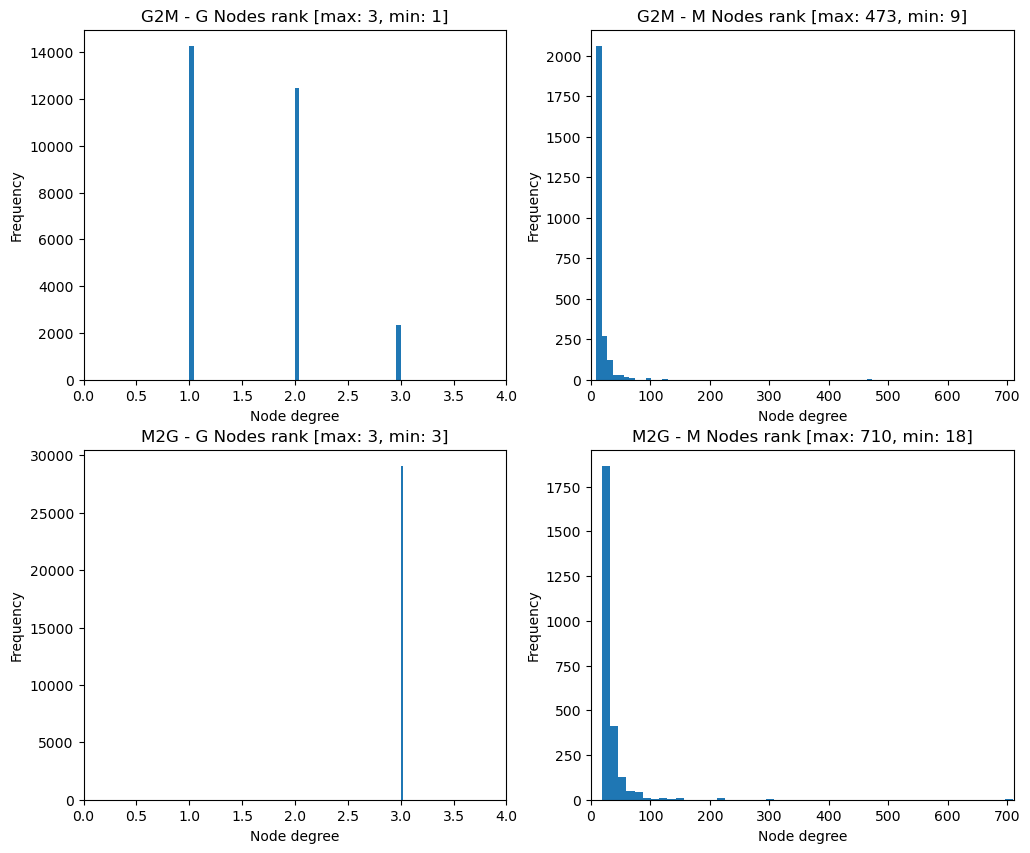

In [20]:
# inspect the distribution of node ranks in g2m and m2g networks
import matplotlib.pyplot as plt
import numpy as np

fig, ax2 = plt.subplots(2,2, figsize=(12, 10))

ax2[0, 0].hist(g2m_statistics["grid_deg"], bins=50)
ax2[0, 0].set_title(f"G2M - G Nodes rank [max: {g2m_statistics['grid_deg'].max().item()}, min: {g2m_statistics['grid_deg'].min().item()}]")
ax2[0, 0].set_xlabel("Node degree")
ax2[0, 0].set_ylabel("Frequency")

ax2[0, 1].hist(g2m_statistics["mesh_deg"], bins=50)
ax2[0, 1].set_title(f"G2M - M Nodes rank [max: {g2m_statistics['mesh_deg'].max().item()}, min: {g2m_statistics['mesh_deg'].min().item()}]")
ax2[0, 1].set_xlabel("Node degree")
ax2[0, 1].set_ylabel("Frequency")

ax2[1, 0].hist(m2g_statistics["grid_deg"], bins=50)
ax2[1, 0].set_title(f"M2G - G Nodes rank [max: {m2g_statistics['grid_deg'].max().item()}, min: {m2g_statistics['grid_deg'].min().item()}]")
ax2[1, 0].set_xlabel("Node degree")
ax2[1, 0].set_ylabel("Frequency")

ax2[1, 1].hist(m2g_statistics["mesh_deg"], bins=50)
ax2[1, 1].set_title(f"M2G - M Nodes rank [max: {m2g_statistics['mesh_deg'].max().item()}, min: {m2g_statistics['mesh_deg'].min().item()}]")
ax2[1, 1].set_xlabel("Node degree")
ax2[1, 1].set_ylabel("Frequency")  

# set axs[0,0] and axs[1,0] to have the same xlim and axs[0,1] and axs[1,1] to have the same xlim
ax2[0, 0].set_xlim(0, max(max(g2m_statistics["grid_deg"]), max(m2g_statistics["grid_deg"])) + 1)
ax2[1, 0].set_xlim(0, max(max(g2m_statistics["grid_deg"]), max(m2g_statistics["grid_deg"])) + 1)
ax2[0, 1].set_xlim(0, max(max(g2m_statistics["mesh_deg"]), max(m2g_statistics["mesh_deg"])) + 1)
ax2[1, 1].set_xlim(0, max(max(g2m_statistics["mesh_deg"]), max(m2g_statistics["mesh_deg"])) + 1)    

In [21]:
# inspect the distribution of edge lengths in g2m and m2g networks

fig, ax2 = plt.subplots(2,2, figsize=(12, 10))

ax2[0, 0].hist(g2m_statistics["lengths"], bins=50)
ax2[0, 0].set_title(f"G2M - G Edges length [max: {round(g2m_statistics['lengths'].max().item(), 2)}, min: {round(g2m_statistics['lengths'].min().item(), 2)}]")
ax2[0, 0].set_xlabel("Edge length")
ax2[0, 0].set_ylabel("Frequency") 

ax2[0, 1].hist(g2m_statistics["lengths"], bins=50)
ax2[0, 1].set_title(f"G2M - M Edges length [max: {round(g2m_statistics['lengths'].max().item(), 2)}, min: {round(g2m_statistics['lengths'].min().item(), 2)}]")
ax2[0, 1].set_xlabel("Edge length")
ax2[0, 1].set_ylabel("Frequency")

ax2[1, 0].hist(m2g_statistics["lengths"], bins=50)
ax2[1, 0].set_title(f"M2G - G Edges length [max: {round(m2g_statistics['lengths'].max().item(), 2)}, min: {round(m2g_statistics['lengths'].min().item(), 2)}]")
ax2[1, 0].set_xlabel("Edge length")
ax2[1, 0].set_ylabel("Frequency")

ax2[1, 1].hist(m2g_statistics["lengths"], bins=50)
ax2[1, 1].set_title(f"M2G - M Edges length [max: {round(m2g_statistics['lengths'].max().item(), 2)}, min: {round(m2g_statistics['lengths'].min().item(), 2)}]")
ax2[1, 1].set_xlabel("Edge length")
ax2[1, 1].set_ylabel("Frequency")

Text(0, 0.5, 'Frequency')

Most probably 316 is the thereshold used to build the encoder graph and 520 the one for the decoder graph